In [1]:
!pip install openpyxl

import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd

df = pd.read_excel('/content/Bank_Churn_ML_Prepared.xlsx')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (10000, 15)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Balance_Salary_Ratio,Product_Density,Engaement_Product,Age_Tenure_Interaction
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0.000000,0,1,84
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0.744677,0,1,41
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1.401375,1,0,336
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0.000000,1,0,39
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,1.587055,0,1,86


In [3]:
# Check dataset information
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check target variable distribution
print("\nChurn Distribution:")
print(df['Exited'].value_counts())

# Check churn percentage
print("\nChurn Percentage:")
print(df['Exited'].value_counts(normalize=True) * 100)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CreditScore             10000 non-null  int64  
 1   Geography               10000 non-null  object 
 2   Gender                  10000 non-null  object 
 3   Age                     10000 non-null  int64  
 4   Tenure                  10000 non-null  int64  
 5   Balance                 10000 non-null  float64
 6   NumOfProducts           10000 non-null  int64  
 7   HasCrCard               10000 non-null  int64  
 8   IsActiveMember          10000 non-null  int64  
 9   EstimatedSalary         10000 non-null  float64
 10  Exited                  10000 non-null  int64  
 11  Balance_Salary_Ratio    10000 non-null  float64
 12  Product_Density         10000 non-null  int64  
 13  Engaement_Product       10000 non-null  int64  
 14  Age_Tenure_Interaction  10000 non-null 

In [5]:
df.rename(columns={
    'Engaement_Product': 'Engagement_Product'
}, inplace=True)

print(df.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Balance_Salary_Ratio', 'Product_Density', 'Engagement_Product', 'Age_Tenure_Interaction']


In [6]:
# Separate input features and target variable

X = df.drop('Exited', axis=1)

y = df['Exited']

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

Input features shape: (10000, 14)
Target variable shape: (10000,)


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (8000, 14)
Testing features: (2000, 14)
Training target: (8000,)
Testing target: (2000,)


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Identify categorical and numerical columns
categorical_features = ['Geography', 'Gender']

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

# Prepare preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', StandardScaler(), numerical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the training-fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
print("Data preprocessing completed successfully!")

Training data shape: (8000, 17)
Testing data shape: (2000, 17)
Data preprocessing completed successfully!


In [11]:
from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(random_state=42, max_iter=1000)

# Train the model
lr_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [12]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Make predictions
y_pred = lr_model.predict(X_test_processed)

# Get churn probabilities
y_prob = lr_model.predict_proba(X_test_processed)[:, 1]

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.842
Precision: 0.7136150234741784
Recall: 0.37346437346437344
F1 Score: 0.49032258064516127
ROC-AUC: 0.836309344783921

Confusion Matrix:
[[1532   61]
 [ 255  152]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.96      0.91      1593
           1       0.71      0.37      0.49       407

    accuracy                           0.84      2000
   macro avg       0.79      0.67      0.70      2000
weighted avg       0.83      0.84      0.82      2000



In [13]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced',
    max_depth=10
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [14]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Make predictions
rf_pred = rf_model.predict(X_test_processed)

# Get churn probabilities
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]

# Evaluate the model
print("Random Forest Results")
print("----------------------")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Results
----------------------
Accuracy: 0.8385
Precision: 0.5929203539823009
Recall: 0.6584766584766585
F1 Score: 0.6239813736903376
ROC-AUC: 0.8616305056983022

Confusion Matrix:
[[1409  184]
 [ 139  268]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.88      0.90      1593
           1       0.59      0.66      0.62       407

    accuracy                           0.84      2000
   macro avg       0.75      0.77      0.76      2000
weighted avg       0.85      0.84      0.84      2000



In [15]:
import pandas as pd

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get feature importance
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

# Sort from highest to lowest
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df.to_string(index=False))

                    Feature  Importance
                   num__Age    0.256762
         num__NumOfProducts    0.141023
               num__Balance    0.083705
  num__Balance_Salary_Ratio    0.069702
num__Age_Tenure_Interaction    0.067391
       num__EstimatedSalary    0.061301
    num__Engagement_Product    0.061148
           num__CreditScore    0.059113
       num__Product_Density    0.052408
     cat__Geography_Germany    0.036695
                num__Tenure    0.030767
        num__IsActiveMember    0.028078
      cat__Geography_France    0.012890
         cat__Gender_Female    0.011263
           cat__Gender_Male    0.011027
       cat__Geography_Spain    0.008894
             num__HasCrCard    0.007832


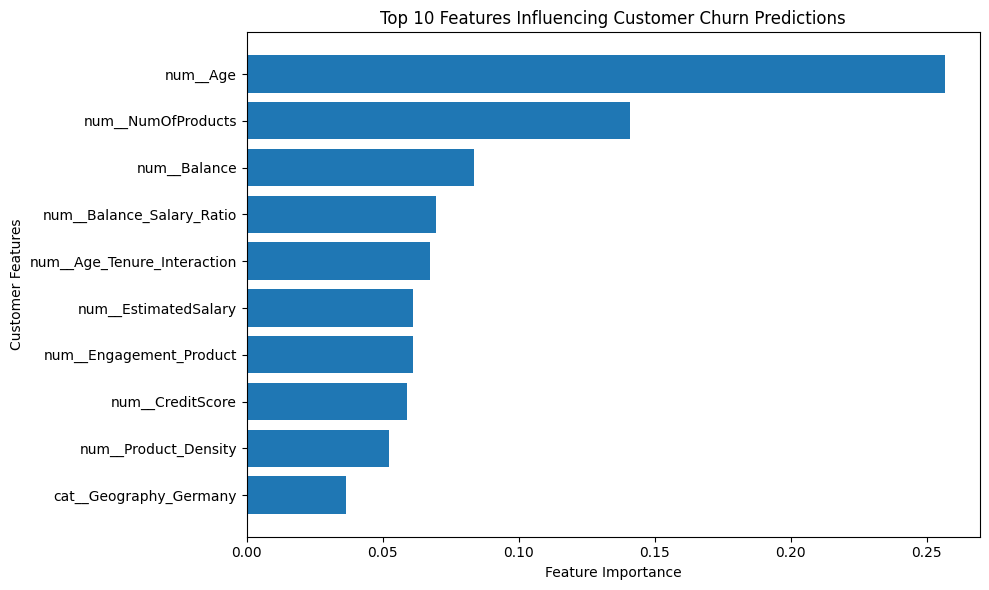

In [16]:
import matplotlib.pyplot as plt

# Select top 10 features
top_features = importance_df.head(10).sort_values(
    by='Importance',
    ascending=True
)

# Create chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title('Top 10 Features Influencing Customer Churn Predictions')
plt.xlabel('Feature Importance')
plt.ylabel('Customer Features')

plt.tight_layout()
plt.show()

In [17]:
import pandas as pd

# Create customer-level prediction report
churn_report = pd.DataFrame({
    'Customer_Row': X_test.index,
    'Actual_Churn': y_test.values,
    'Churn_Probability': rf_prob
})

# Convert probability into percentage
churn_report['Churn_Probability'] = (
    churn_report['Churn_Probability'] * 100
).round(2)

# Assign risk categories
def assign_risk(probability):
    if probability < 30:
        return 'Low Risk'
    elif probability < 60:
        return 'Medium Risk'
    else:
        return 'High Risk'

churn_report['Risk_Category'] = (
    churn_report['Churn_Probability'].apply(assign_risk)
)

# Display first 10 customers
print(churn_report.head(10))

# Count customers in each risk category
print("\nCustomer Risk Summary:")
print(churn_report['Risk_Category'].value_counts())

   Customer_Row  Actual_Churn  Churn_Probability Risk_Category
0          5702             0               5.20      Low Risk
1          3667             0              15.49      Low Risk
2          1617             0              11.04      Low Risk
3          5673             0              14.89      Low Risk
4          4272             0              38.14   Medium Risk
5          8270             0              39.03   Medium Risk
6          7079             0               8.95      Low Risk
7          5295             0              36.83   Medium Risk
8           845             0              69.68     High Risk
9          5311             0              15.63      Low Risk

Customer Risk Summary:
Risk_Category
Low Risk       1139
Medium Risk     550
High Risk       311
Name: count, dtype: int64


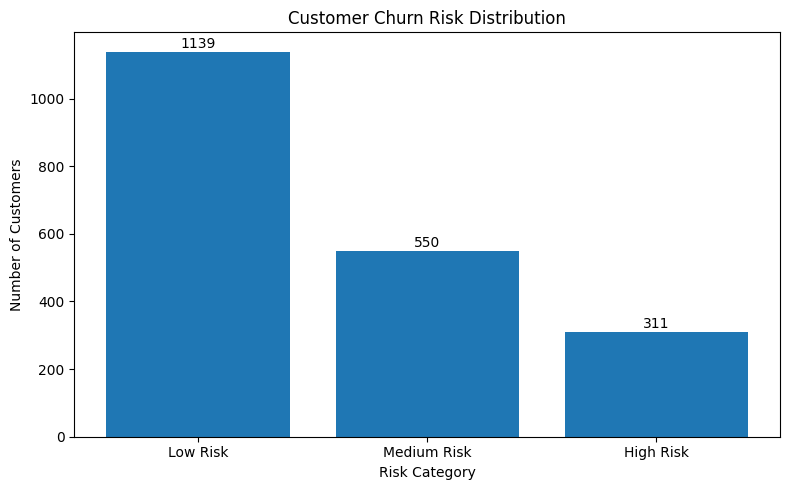

In [18]:
import matplotlib.pyplot as plt

risk_counts = churn_report['Risk_Category'].value_counts().reindex(
    ['Low Risk', 'Medium Risk', 'High Risk']
)

plt.figure(figsize=(8, 5))

plt.bar(risk_counts.index, risk_counts.values)

plt.title('Customer Churn Risk Distribution')
plt.xlabel('Risk Category')
plt.ylabel('Number of Customers')

for i, value in enumerate(risk_counts.values):
    plt.text(i, value + 10, str(value), ha='center')

plt.tight_layout()
plt.show()

In [19]:
churn_report.to_excel(
    'Customer_Churn_Risk_Report.xlsx',
    index=False
)

print("Customer risk report exported successfully!")

Customer risk report exported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [20]:
# Transform the complete dataset
X_all_processed = preprocessor.transform(X)

# Predict churn probabilities for all customers
all_probabilities = rf_model.predict_proba(X_all_processed)[:, 1]

# Create the complete customer risk report
all_customer_report = pd.DataFrame({
    'Customer_Row': X.index,
    'Churn_Probability': (all_probabilities * 100).round(2)
})

# Assign risk categories
all_customer_report['Risk_Category'] = (
    all_customer_report['Churn_Probability'].apply(assign_risk)
)

# Display first 10 records
print(all_customer_report.head(10))

print("\nComplete Customer Risk Summary:")
print(all_customer_report['Risk_Category'].value_counts())

print("\nTotal Customers:", len(all_customer_report))

   Customer_Row  Churn_Probability Risk_Category
0             0              71.68     High Risk
1             1              36.03   Medium Risk
2             2              95.69     High Risk
3             3              16.17      Low Risk
4             4              31.54   Medium Risk
5             5              57.24   Medium Risk
6             6               6.77      Low Risk
7             7              88.23     High Risk
8             8              37.19   Medium Risk
9             9              12.53      Low Risk

Complete Customer Risk Summary:
Risk_Category
Low Risk       5906
Medium Risk    2380
High Risk      1714
Name: count, dtype: int64

Total Customers: 10000


In [21]:
all_customer_report.to_excel(
    'All_10000_Customer_Churn_Risk_Report.xlsx',
    index=False
)

print("Complete customer risk report exported successfully!")

Complete customer risk report exported successfully!
